# Exploratory Data Analysis - Energy

## 0 · Setup
We use the standard Python data stack: **pandas** for tables, **numpy** for numbers, **matplotlib** and **seaborn** for plots.

In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(f"python  {sys.version.split()[0]}")
print(f"pandas  {pd.__version__}")
print(f"numpy   {np.__version__}")
print(f"seaborn {sns.__version__}")

# One consistent look for all plots: light grid, colour-blind-safe palette, readable size
sns.set_theme(style="whitegrid", palette="colorblind", context="notebook")
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

RNG = np.random.default_rng(42)   # any sampling below is reproducible

# Plots for our report go into figures/eda/ 
from pathlib import Path
FIG_DIR = Path("figures/eda")
FIG_DIR.mkdir(parents=True, exist_ok=True)

python  3.15.2
pandas  3.1.0
numpy   2.5.4
seaborn 0.13.2


## 1 · Load the data

In [3]:
df = pd.read_csv("../data/raw data/energy-data.csv")

print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

24,752 rows x 3 columns


,unix_seconds,load,solar
0,1704063600,8983.0,0.0
1,1704067200,8598.7,0.0
2,1704070800,8794.0,0.0
3,1704074400,8869.3,0.0
4,1704078000,8627.0,0.0


### 1.1 Check data type and non-null values

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24752 entries, 0 to 24751
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   unix_seconds  24752 non-null  int64  
 1   load          24751 non-null  float64
 2   solar         24750 non-null  float64
dtypes: float64(2), int64(1)
memory usage: 580.3 KB


### 1.2 `describe()` — numbers *and* text columns

In [5]:
df.describe().round(2)

,unix_seconds,load,solar
count,2.475200e+04,24751.00,24750.00
mean,1.748615e+09,7693.20,933.83
std,2.572355e+07,1147.87,1473.64
min,1.704064e+09,3065.80,0.00
25%,1.726340e+09,6911.30,0.00
50%,1.748615e+09,7721.30,34.95
75%,1.770891e+09,8487.10,1383.15
max,1.793167e+09,12234.10,6630.10


## 2 · Tidy names and types

Dataset already contains consistent lowercase `snake_case` names

## 3 · Data quality

### 3.1 How much is missing, and where?

In [6]:
missing = (df.isna().sum().to_frame("n_missing")
             .assign(pct_missing=lambda t: (100 * t["n_missing"] / len(df)).round(1))
             .query("n_missing > 0")
             .sort_values("pct_missing", ascending=False))
missing

,n_missing,pct_missing
load,1,0.0
solar,2,0.0


### 3.2 Duplicates

In [7]:
print("exact duplicate rows      :", df.duplicated().sum())

exact duplicate rows      : 0


### 3.4 Impossible or suspicious values

(no impossible or suspicious values found)

In [8]:
df.describe().round(2)

,unix_seconds,load,solar
count,2.475200e+04,24751.00,24750.00
mean,1.748615e+09,7693.20,933.83
std,2.572355e+07,1147.87,1473.64
min,1.704064e+09,3065.80,0.00
25%,1.726340e+09,6911.30,0.00
50%,1.748615e+09,7721.30,34.95
75%,1.770891e+09,8487.10,1383.15
max,1.793167e+09,12234.10,6630.10


## 4 · Why is it missing?

The full dataset contains one missing value in load and two in solar. 

The final row is entirely empty, and the second-to-last row is missing its solar value. 

Filtering to 2025 excludes both rows, so no imputation is needed.

In [9]:
missing

,n_missing,pct_missing
load,1,0.0
solar,2,0.0


## 5 · One variable at a time

We group the 2025 electricity load measurements by local hour to compare their distributions across the day.

In [10]:
local_time = pd.to_datetime(df["unix_seconds"], unit="s", utc=True).dt.tz_convert("Europe/Zurich")

eda_2025 = (
    df.assign(local_time=local_time)
      .loc[local_time.dt.year == 2025]
      .copy()
)
eda_2025["hour"] = eda_2025["local_time"].dt.hour
eda_2025["month"] = eda_2025["local_time"].dt.month

print("First timestamp:", eda_2025["local_time"].min())
print("Last timestamp: ", eda_2025["local_time"].max())

First timestamp: 2025-01-01 00:00:00+01:00
Last timestamp:  2025-12-31 23:00:00+01:00


### 5.2 At what time of day is Swiss electricity load highest?

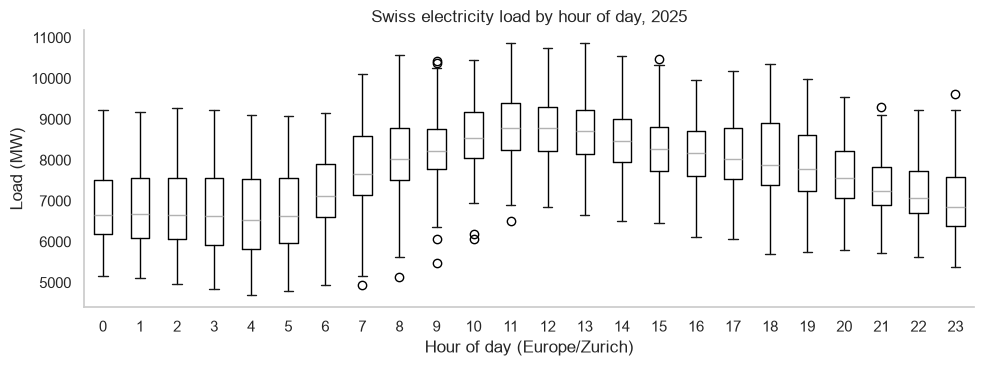

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
eda_2025.boxplot(column="load", by="hour", ax=ax, grid=False)
fig.suptitle("")
ax.set(title="Swiss electricity load by hour of day, 2025",
       xlabel="Hour of day (Europe/Zurich)", ylabel="Load (MW)")
plt.tight_layout()
plt.savefig('../figures/eda/swiss_electricity_load_by_hour.png', dpi=300, bbox_inches='tight')
plt.show()

- Median load rises from about **6,500 MW at 04:00** to **8,800 MW around 11:00–12:00**, then gradually falls to about **6,800 MW by 23:00**.

- Load also varies from day to day. At **04:00**, for example, the middle half of observations ranges from roughly **5,800 to 7,500 MW**.

- Each box pools all days of 2025 at the same local hour. The midday peak describes the **hourly medians**. Individual days can peak at different times.

### 5.3 How much does Swiss solar generation vary at each hour?


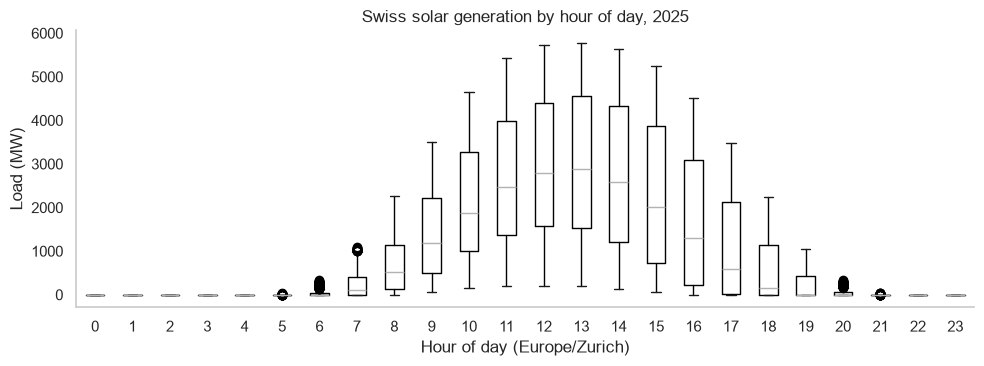

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
eda_2025.boxplot(column="solar", by="hour", ax=ax, grid=False)
fig.suptitle("")
ax.set(title="Swiss solar generation by hour of day, 2025",
       xlabel="Hour of day (Europe/Zurich)", ylabel="Load (MW)")
plt.tight_layout()
plt.savefig('../figures/eda/swiss_solar_generation_by_hour.png', dpi=300, bbox_inches='tight')
plt.show()

- Median solar generation is close to **zero overnight** and peaks at about **2,900 MW around 13:00** before falling through the afternoon.

- The spread is widest around midday. At **13:00**, the middle half of observations ranges from roughly **1,500 to 4,600 MW**. Even at the same hour, output varies substantially across days.

- At **06:00** and **20:00**, some days show positive generation even though the median is near zero. Because the plot combines all seasons, these points can reflect longer summer daylight hours.